<div align="center">

### Lab 03 | Neural Coding: From Spikes to Information

**Student ID:** MS26901626 · **Name:** P. K. A. Lakshan

---

**Programming Environment:** Python  
**Libraries:** NumPy • Matplotlib  

</div>

---

#### Learning Outcomes

By completing this lab, you will be able to:

1.	Explain the difference between rate coding and temporal coding
2.  Simulate spike trains using probabilistic models
3.  Understand how refractory periods limit firing rates
4.  Analyze inter-spike intervals (ISI)
5.  Demonstrate how population size improves decoding accuracy
6.  Interpret how biological constraints shape neural information processing

### Part A — Spike trains as a code (Poisson model)
Goal: Show that spikes are discrete events and coding often happens in rate or timing.

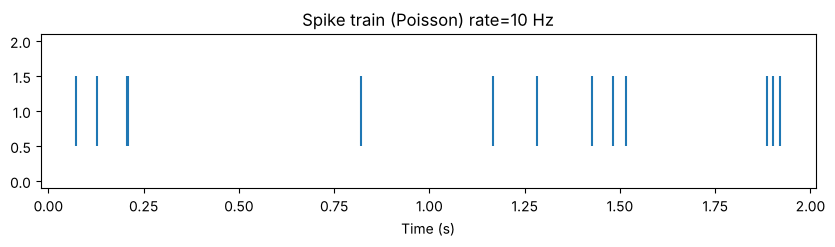

Estimated rate (Hz): 6.5


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

T = 2.0          # seconds
dt = 0.001       # 1 ms
t = np.arange(0, T, dt)

def poisson_spikes(rate_hz, t, dt):
    p = rate_hz * dt
    return (np.random.rand(len(t)) < p).astype(int)

rate = 10  # Hz
spikes = poisson_spikes(rate, t, dt)

plt.figure(figsize=(10,2))
plt.eventplot(t[spikes==1])
plt.title(f"Spike train (Poisson) rate={rate} Hz")
plt.xlabel("Time (s)")
plt.show()

print("Estimated rate (Hz):", spikes.sum()/T)

#### TODO 1 — Different rates + sliding-window rate estimator
For rate = 5, 20, 50 Hz: raster (10 trials each) and the estimated rate (spike count / T). The sliding-window estimator is a moving average of the spike train: r̂(t) = (spikes in a window of width w centred on t) / w, with w = 200 ms.

rate  5 Hz: estimated over 2 s (10 trials) =   4.5 ±  0.6 Hz, relative error 12.6% | sliding estimate range 0–20 Hz
rate 20 Hz: estimated over 2 s (10 trials) =  19.2 ±  2.3 Hz, relative error 11.5% | sliding estimate range 5–35 Hz
rate 50 Hz: estimated over 2 s (10 trials) =  50.1 ±  4.9 Hz, relative error  9.7% | sliding estimate range 10–80 Hz


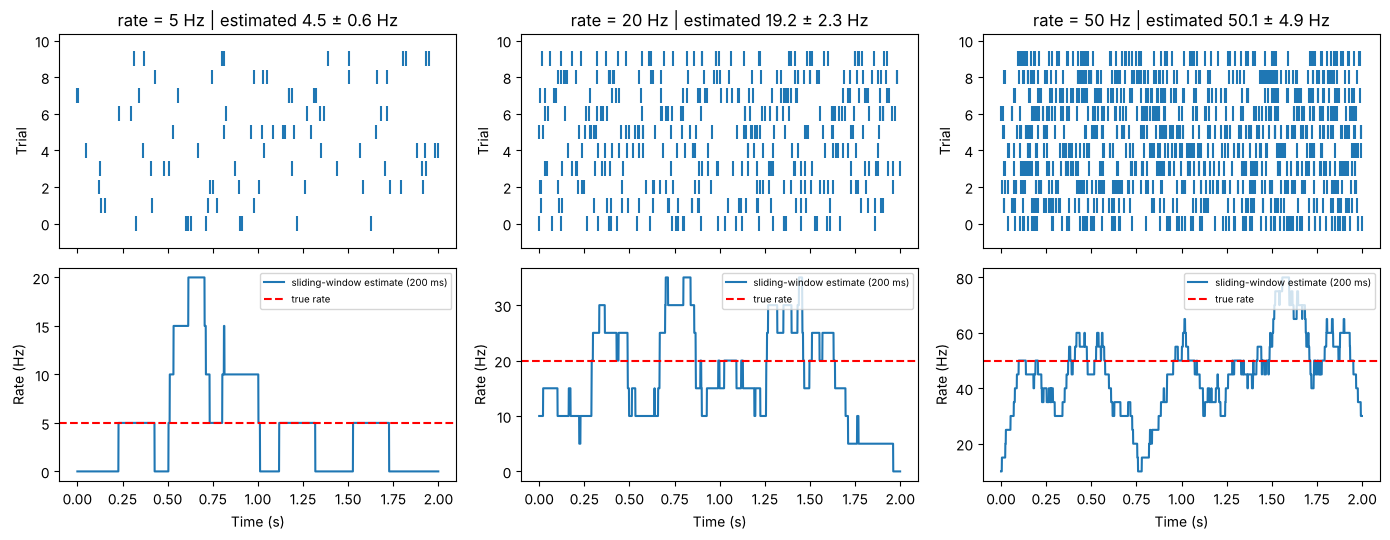

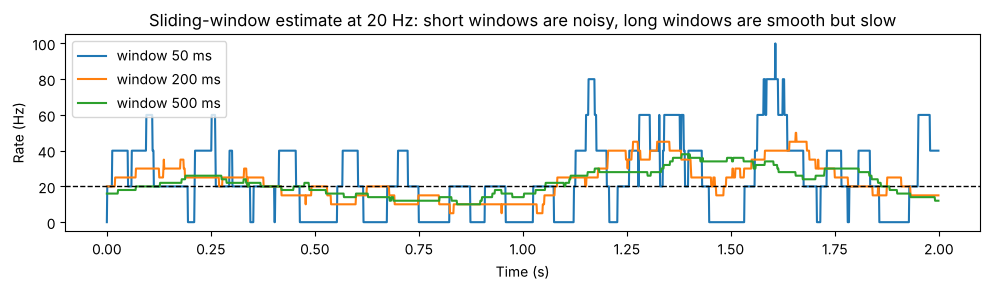

In [2]:
# TODO 1:
# Change rate = 5, 20, 50 and observe the raster + estimated rate.
#Add a rate estimator using a sliding window (students implement a simple moving average).

def sliding_rate(spike_train, dt, window_s=0.2):
    """Moving-average firing rate (Hz): spikes inside a window of window_s, divided by window_s."""
    w = int(round(window_s / dt))
    kernel = np.ones(w) / (w * dt)            # box kernel normalised to Hz
    return np.convolve(spike_train, kernel, mode='same')

rates_test = [5, 20, 50]
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex=True)
for k, r in enumerate(rates_test):
    trials = [poisson_spikes(r, t, dt) for _ in range(10)]
    axes[0, k].eventplot([t[tr == 1] for tr in trials], linelengths=0.8)
    est = [tr.sum() / T for tr in trials]
    axes[0, k].set_title(f"rate = {r} Hz | estimated {np.mean(est):.1f} ± {np.std(est):.1f} Hz")
    axes[0, k].set_ylabel("Trial")
    sr = sliding_rate(trials[0], dt, 0.2)
    axes[1, k].plot(t, sr, label="sliding-window estimate (200 ms)")
    axes[1, k].axhline(r, color='r', ls='--', label="true rate")
    axes[1, k].set_xlabel("Time (s)"); axes[1, k].set_ylabel("Rate (Hz)")
    axes[1, k].legend(fontsize=7, loc='upper right')
    print(f"rate {r:>2} Hz: estimated over 2 s (10 trials) = {np.mean(est):5.1f} ± {np.std(est):4.1f} Hz, "
          f"relative error {np.std(est)/r*100:4.1f}% | sliding estimate range {sr[100:-100].min():.0f}–{sr[100:-100].max():.0f} Hz")
plt.tight_layout(); plt.show()

# Window size trade-off (rate 20 Hz)
tr = poisson_spikes(20, t, dt)
plt.figure(figsize=(10, 3))
for w in [0.05, 0.2, 0.5]:
    plt.plot(t, sliding_rate(tr, dt, w), label=f"window {int(w*1000)} ms")
plt.axhline(20, color='k', ls='--', lw=1); plt.xlabel("Time (s)"); plt.ylabel("Rate (Hz)")
plt.title("Sliding-window estimate at 20 Hz: short windows are noisy, long windows are smooth but slow")
plt.legend(); plt.tight_layout(); plt.show()

### Part B — Refractory period (biophysical constraint)
Goal : Show that biology imposes limits on maximum firing rate.

In [3]:
def poisson_spikes_with_refractory(rate_hz, t, dt, refrac_s=0.01):
    p = rate_hz * dt
    spikes = np.zeros(len(t), dtype=int)
    last_spike_t = -np.inf
    for i, ti in enumerate(t):
        if (ti - last_spike_t) >= refrac_s:
            if np.random.rand() < p:
                spikes[i] = 1
                last_spike_t = ti
    return spikes

rate = 80
sp_no_ref = poisson_spikes(rate, t, dt)
sp_ref = poisson_spikes_with_refractory(rate, t, dt, refrac_s=0.01)

print("No ref rate:", sp_no_ref.sum()/T)
print("With ref rate:", sp_ref.sum()/T)

No ref rate: 82.5
With ref rate: 43.0


#### TODO 2 — Refractory period: achieved rate and ISI distribution
Input rate 80 Hz (and 200 Hz to show the ceiling) with refractory periods of 0, 2, 5, 10 ms, averaged over 20 trials. The ISI (inter-spike interval) is the time between consecutive spikes: `np.diff(spike_times)`.

input  80 Hz, refractory    0 ms → achieved   80.4 Hz 
input  80 Hz, refractory    2 ms → achieved   74.8 Hz (max possible 1/τ = 500 Hz)
input  80 Hz, refractory    5 ms → achieved   58.0 Hz (max possible 1/τ = 200 Hz)
input  80 Hz, refractory   10 ms → achieved   46.2 Hz (max possible 1/τ = 100 Hz)
input 200 Hz, refractory    0 ms → achieved  200.2 Hz 
input 200 Hz, refractory    2 ms → achieved  164.5 Hz (max possible 1/τ = 500 Hz)
input 200 Hz, refractory    5 ms → achieved  107.1 Hz (max possible 1/τ = 200 Hz)
input 200 Hz, refractory   10 ms → achieved   71.2 Hz (max possible 1/τ = 100 Hz)


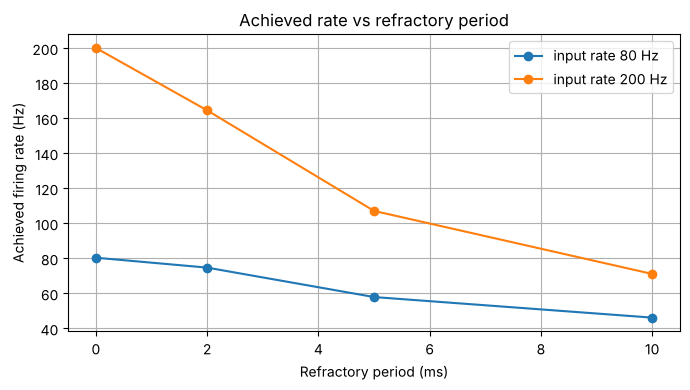

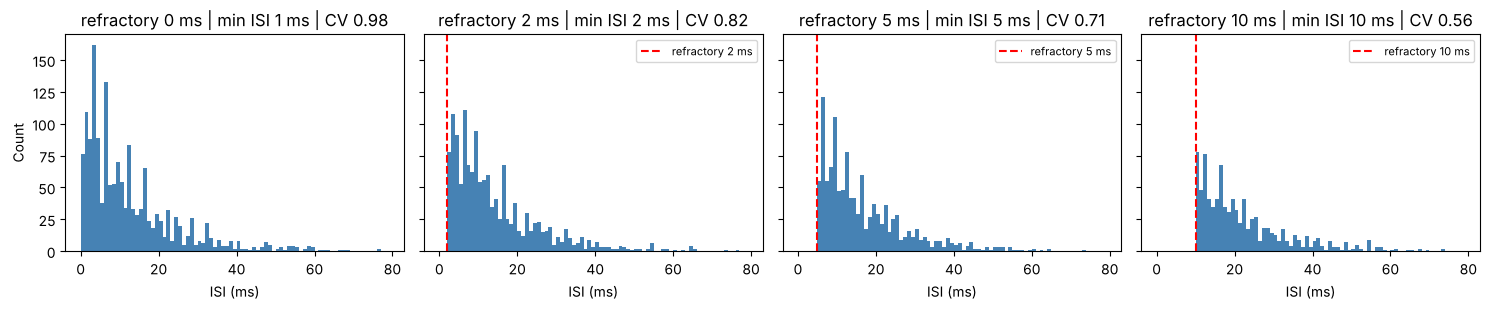

In [4]:
# TODO 2:
# Vary refrac_s (2ms, 5ms, 10ms) and plot achieved firing rate vs refractory.
#Compute ISI (inter-spike interval) distribution and show the “gap” caused by refractory.
#(You must write the ISI code.)
#What happen when refactor increase?

def isi(spike_train, t):
    """Inter-spike intervals (s) of a binary spike train."""
    times = t[spike_train == 1]
    return np.diff(times)

refracs = [0.0, 0.002, 0.005, 0.010]
plt.figure(figsize=(7, 4))
for input_rate in [80, 200]:
    achieved = []
    for rf in refracs:
        runs = [poisson_spikes_with_refractory(input_rate, t, dt, rf).sum() / T for _ in range(20)]
        achieved.append(np.mean(runs))
    plt.plot([r*1000 for r in refracs], achieved, 'o-', label=f"input rate {input_rate} Hz")
    for rf, a in zip(refracs, achieved):
        cap = f"(max possible 1/τ = {1/rf:.0f} Hz)" if rf > 0 else ""
        print(f"input {input_rate:>3} Hz, refractory {rf*1000:>4.0f} ms → achieved {a:6.1f} Hz {cap}")
plt.xlabel("Refractory period (ms)"); plt.ylabel("Achieved firing rate (Hz)")
plt.title("Achieved rate vs refractory period"); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# ISI distributions at 80 Hz input: the 'gap' below the refractory period
T_long = 20.0; t_long = np.arange(0, T_long, dt)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, rf in zip(axes, refracs):
    tr = poisson_spikes_with_refractory(80, t_long, dt, rf) if rf > 0 else poisson_spikes(80, t_long, dt)
    d = isi(tr, t_long) * 1000
    ax.hist(d, bins=np.arange(0, 80, 1), color='steelblue')
    if rf > 0: ax.axvline(rf*1000, color='r', ls='--', label=f"refractory {rf*1000:.0f} ms")
    ax.set_title(f"refractory {rf*1000:.0f} ms | min ISI {d.min():.0f} ms | CV {d.std()/d.mean():.2f}")
    ax.set_xlabel("ISI (ms)")
    if rf > 0: ax.legend(fontsize=8)
axes[0].set_ylabel("Count")
plt.tight_layout(); plt.show()

**What happens when the refractory period increases?** The achieved firing rate falls below the input rate and is capped at 1/τ_ref: with 80 Hz input it drops progressively as τ grows, and with 200 Hz input it stays well below 200 Hz. The ISI histogram has an empty **gap** below τ_ref (no interval shorter than the refractory period), so short intervals are removed. Spike trains become more regular: the coefficient of variation (CV) falls below 1, the value for a pure Poisson process.

### Part C — Rate coding experiment (stimulus intensity → firing rate)

Goal: Show “intensity” is encoded by spike rate, not spike amplitude.

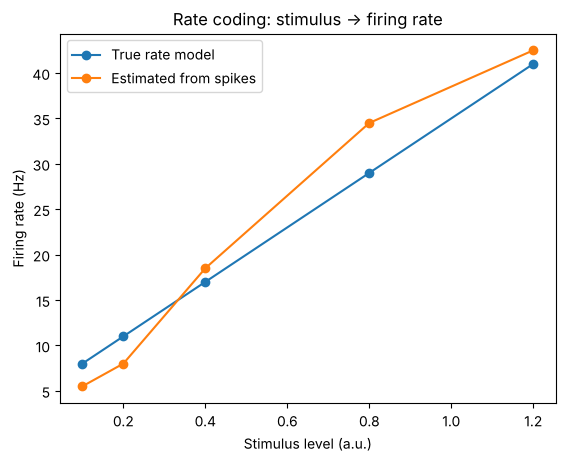

In [5]:
stim_levels = np.array([0.1, 0.2, 0.4, 0.8, 1.2])  # arbitrary stimulus
base = 5
gain = 30

rates = base + gain*stim_levels  # simple encoding model

estimated = []
for r in rates:
    sp = poisson_spikes(r, t, dt)
    estimated.append(sp.sum()/T)

plt.figure()
plt.plot(stim_levels, rates, marker='o', label="True rate model")
plt.plot(stim_levels, estimated, marker='o', label="Estimated from spikes")
plt.xlabel("Stimulus level (a.u.)")
plt.ylabel("Firing rate (Hz)")
plt.title("Rate coding: stimulus → firing rate")
plt.legend()
plt.show()

#### TODO 3 — Nonlinear (sigmoid) encoding + stimulus noise
Sigmoid encoding with saturation: r(s) = r_min + (r_max − r_min) / (1 + e^(−k(s − s₀))), with r_min = 5 Hz, r_max = 60 Hz, k = 6, s₀ = 0.5. Noise: the stimulus fluctuates around its level with Gaussian noise (σ = 0, 0.1, 0.3), redrawn every 50 ms. Each condition has 30 trials of 2 s.

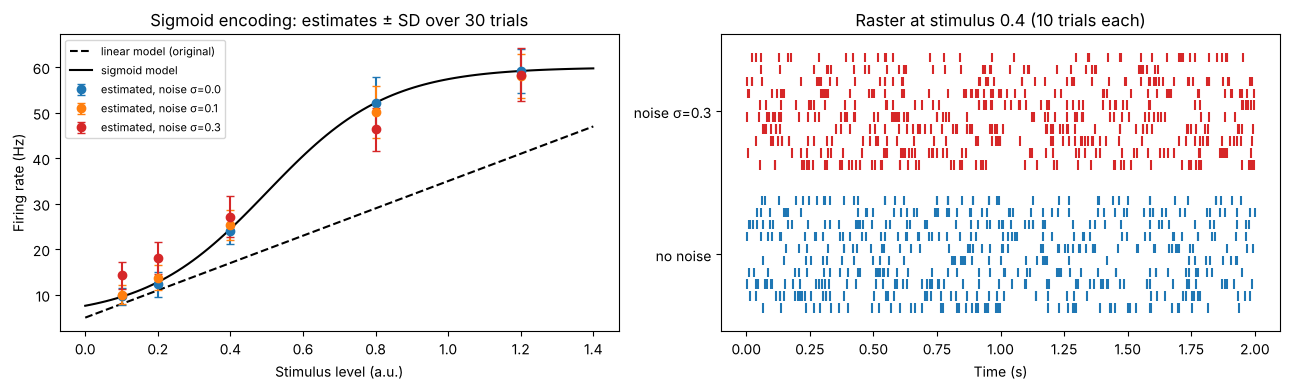

Stimulus:             [0.1 0.2 0.4 0.8 1.2]
Sigmoid true rate:    [ 9.6 12.8 24.5 52.2 59.2]
σ=0.0: mean est.   [ 9.7 12.3 24.1 52.1 59.2] | SD [1.8 2.7 2.8 5.9 4.9]
σ=0.1: mean est.   [10.  13.8 25.3 50.2 58. ] | SD [2.1 2.8 3.3 5.7 4.9]
σ=0.3: mean est.   [14.3 18.1 27.2 46.4 58.4] | SD [2.9 3.4 4.5 4.7 5.8]
Rate difference between stimulus 0.8 and 1.2 (sigmoid): 7.0 Hz vs linear: 12.0 Hz


In [6]:
# TODO 3:
#Modify the encoding model: make it nonlinear (e.g., sigmoid or saturation).
#Add noise to stimulus and check stability of rate estimation.
#Explain what happen to the Raster plot and rate estimation. (1-2 sentenses)

def sigmoid_rate(s, rmin=5, rmax=60, k=6, s0=0.5):
    return rmin + (rmax - rmin) / (1 + np.exp(-k * (s - s0)))

def spikes_time_varying(rate_t, dt):
    return (np.random.rand(len(rate_t)) < rate_t * dt).astype(int)

def noisy_stimulus(level, sigma, t, hold_s=0.05):
    n_hold = int(hold_s / dt)
    noise = np.repeat(np.random.randn(int(np.ceil(len(t) / n_hold))) * sigma, n_hold)[:len(t)]
    return level + noise

s_grid = np.linspace(0, 1.4, 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(s_grid, base + gain * s_grid, 'k--', label="linear model (original)")
axes[0].plot(s_grid, sigmoid_rate(s_grid), 'k-', label="sigmoid model")
summary = {}
for sigma, col in [(0.0, 'C0'), (0.1, 'C1'), (0.3, 'C3')]:
    means, sds = [], []
    for s in stim_levels:
        est = [spikes_time_varying(sigmoid_rate(noisy_stimulus(s, sigma, t)), dt).sum() / T for _ in range(30)]
        means.append(np.mean(est)); sds.append(np.std(est))
    summary[sigma] = (means, sds)
    axes[0].errorbar(stim_levels, means, yerr=sds, fmt='o', color=col, capsize=3, label=f"estimated, noise σ={sigma}")
axes[0].set_xlabel("Stimulus level (a.u.)"); axes[0].set_ylabel("Firing rate (Hz)")
axes[0].set_title("Sigmoid encoding: estimates ± SD over 30 trials"); axes[0].legend(fontsize=8)

# Raster at stimulus 0.4 with and without noise
for row, sigma in enumerate([0.0, 0.3]):
    trials = [spikes_time_varying(sigmoid_rate(noisy_stimulus(0.4, sigma, t)), dt) for _ in range(10)]
    axes[1].eventplot([t[tr == 1] for tr in trials], lineoffsets=np.arange(10) + row * 12, linelengths=0.8,
                      colors='C0' if sigma == 0 else 'C3')
axes[1].set_yticks([4.5, 16.5]); axes[1].set_yticklabels(["no noise", "noise σ=0.3"])
axes[1].set_xlabel("Time (s)"); axes[1].set_title("Raster at stimulus 0.4 (10 trials each)")
plt.tight_layout(); plt.show()

print("Stimulus:            ", stim_levels)
print("Sigmoid true rate:   ", np.round(sigmoid_rate(stim_levels), 1))
for sigma, (m, s) in summary.items():
    print(f"σ={sigma}: mean est.  ", np.round(m, 1), "| SD", np.round(s, 1))
print("Rate difference between stimulus 0.8 and 1.2 (sigmoid):", round(sigmoid_rate(1.2) - sigmoid_rate(0.8), 1), "Hz",
      "vs linear:", round(gain * 0.4, 1), "Hz")

**What happened to the raster and the rate estimation?** Intensity is still coded by spike *rate*, but the sigmoid saturates near 60 Hz: stimuli 0.8 and 1.2 give 52 vs 59 Hz (7 Hz apart, against 12 Hz in the linear model), so strong stimuli become hard to tell apart, while the steep middle separates 0.2 from 0.4 well (13 vs 25 Hz). With stimulus noise (σ = 0.3) the raster shows bursts and gaps instead of steady firing, the trial-to-trial SD of the estimate grows (e.g. 1.8 → 2.9 Hz at stimulus 0.1, 2.8 → 4.5 Hz at 0.4), and the mean is biased by the curve's shape (9.7 → 14.3 Hz at 0.1, 52 → 46 Hz at 0.8). Rate estimates become less stable and need longer windows or more trials.

### Part D — Timing code (precision/jitter matters)
Goal: Show that information can be carried by precise spike timing, not just counts.

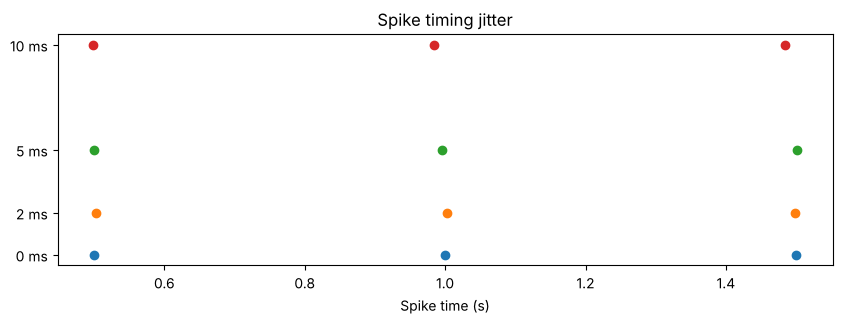

In [7]:
def jitter_spike_times(spike_times, jitter_std, rng=np.random):
    return spike_times + rng.normal(0, jitter_std, size=len(spike_times))

true_times = np.array([0.5, 1.0, 1.5])  # “coded” event times
jitters = [0.0, 0.002, 0.005, 0.01]      # 0–10 ms jitter

plt.figure(figsize=(10,3))
for j in jitters:
    obs = jitter_spike_times(true_times, j)
    plt.plot(obs, np.ones_like(obs)*j, 'o')
plt.yticks(jitters, [f"{int(j*1000)} ms" for j in jitters])
plt.xlabel("Spike time (s)")
plt.title("Spike timing jitter")
plt.show()

#### TODO 4 — Coincidence detector
A coincidence detector "fires" for a target time if a spike arrives within ±w of it. Detection rate = fraction of target events detected over 500 repetitions, for jitter 0–20 ms and windows w = 2, 5, 10 ms. Theory for Gaussian jitter σ: P(detect) = erf(w / (σ√2)).

window ± 2 ms: 0ms→1.00 1ms→0.95 2ms→0.68 3ms→0.48 5ms→0.30 7ms→0.20 10ms→0.14 15ms→0.11 20ms→0.08
window ± 5 ms: 0ms→1.00 1ms→1.00 2ms→0.99 3ms→0.90 5ms→0.68 7ms→0.51 10ms→0.42 15ms→0.28 20ms→0.20


window ±10 ms: 0ms→1.00 1ms→1.00 2ms→1.00 3ms→1.00 5ms→0.96 7ms→0.81 10ms→0.67 15ms→0.49 20ms→0.38


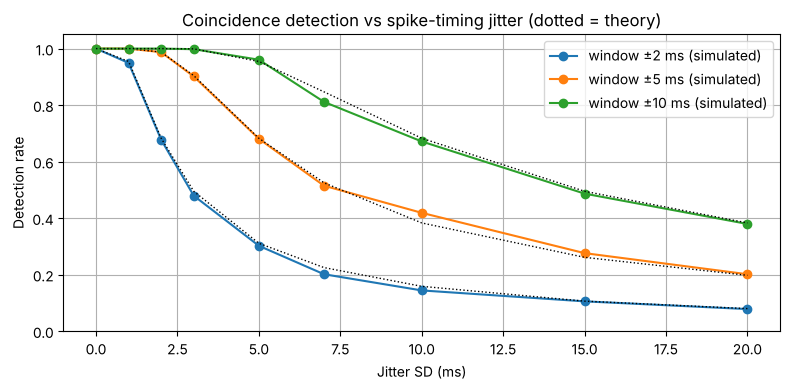

In [8]:
# TODO 4:
#Implement a coincidence detector: count how often spikes fall within a window of a target time.
#Plot detection rate vs jitter.
from math import erf, sqrt

def coincidence_detector(spike_times, target_times, window_s):
    """For each target, 1 if any spike lies within ±window_s of it. Returns the fraction detected."""
    hits = [np.any(np.abs(spike_times - tt) <= window_s) for tt in target_times]
    return np.mean(hits)

jitter_grid = np.array([0, 1, 2, 3, 5, 7, 10, 15, 20]) / 1000
plt.figure(figsize=(8, 4))
for w in [0.002, 0.005, 0.010]:
    rate_det = [np.mean([coincidence_detector(jitter_spike_times(true_times, j), true_times, w) for _ in range(500)])
                for j in jitter_grid]
    plt.plot(jitter_grid * 1000, rate_det, 'o-', label=f"window ±{int(w*1000)} ms (simulated)")
    theory = [1.0 if j == 0 else erf(w / (j * sqrt(2))) for j in jitter_grid]
    plt.plot(jitter_grid * 1000, theory, 'k:', lw=1)
    print(f"window ±{int(w*1000):>2} ms:", " ".join(f"{int(j*1000)}ms→{d:.2f}" for j, d in zip(jitter_grid, rate_det)))
plt.xlabel("Jitter SD (ms)"); plt.ylabel("Detection rate"); plt.ylim(0, 1.05)
plt.title("Coincidence detection vs spike-timing jitter (dotted = theory)"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

Detection is perfect with no jitter and falls as jitter grows, faster for narrow windows: with a ±2 ms window, 5 ms of jitter already loses most events. A timing code is only as good as its precision, and a coincidence detector trades temporal precision (narrow window) against robustness to jitter (wide window).

### Part E — Population coding + simple decoding
Goal: Show that populations reduce noise and enable decoding.

#### Baseline (run): We simulate two stimuli A and B that produce different population rates.

In [9]:
def simulate_population(stim, N=30, T=1.0, dt=0.001):
    t = np.arange(0, T, dt)
    # different rate patterns across neurons
    if stim == "A":
        rates = np.linspace(5, 25, N)
    else:
        rates = np.linspace(25, 5, N)
    spikes = np.array([poisson_spikes(r, t, dt) for r in rates])
    features = spikes.sum(axis=1) / T  # firing rate per neuron (Hz)
    return features

# dataset
X = []
y = []
for _ in range(200):
    X.append(simulate_population("A"))
    y.append(0)
    X.append(simulate_population("B"))
    y.append(1)

X = np.array(X)
y = np.array(y)

# simple linear decoder (no sklearn)
w = X[y==1].mean(axis=0) - X[y==0].mean(axis=0)
b = -0.5 * (X[y==1].mean(axis=0) + X[y==0].mean(axis=0)) @ w

pred = ((X @ w + b) > 0).astype(int)
acc = (pred == y).mean()
print("Decoding accuracy:", acc)

Decoding accuracy: 1.0


#### TODO 5 — Population size and shared (correlated) noise
* The baseline uses 1 s of spikes and gets 100% accuracy, so the task is too easy to show anything. I test N = 5, 10, 20, 50 with 1 s, 100 ms and 50 ms decoding windows.
* The decoder is trained on half the trials and **tested on the other half** (the baseline tested on its own training data).
* **Shared noise**: on each trial all neurons receive a common fluctuation c ~ N(0, σ²) that pushes the whole population pattern towards the other stimulus: rates = r_stim + c·(r_other − r_stim). This correlated noise lies along the direction the decoder uses, so averaging over more neurons cannot remove it.

independent noise, window 1000 ms: {5: np.float64(1.0), 10: np.float64(1.0), 20: np.float64(1.0), 50: np.float64(1.0)}


independent noise, window  100 ms: {5: np.float64(0.915), 10: np.float64(0.945), 20: np.float64(0.99), 50: np.float64(1.0)}


independent noise, window   50 ms: {5: np.float64(0.82), 10: np.float64(0.895), 20: np.float64(0.955), 50: np.float64(0.99)}


shared σ=0.0, window 100 ms: {5: np.float64(0.905), 10: np.float64(0.94), 20: np.float64(0.99), 50: np.float64(1.0)} | ceiling P(c<0.5) = 1.00


shared σ=0.3, window 100 ms: {5: np.float64(0.845), 10: np.float64(0.845), 20: np.float64(0.91), 50: np.float64(0.905)} | ceiling P(c<0.5) = 0.95


shared σ=0.5, window 100 ms: {5: np.float64(0.765), 10: np.float64(0.825), 20: np.float64(0.785), 50: np.float64(0.805)} | ceiling P(c<0.5) = 0.84


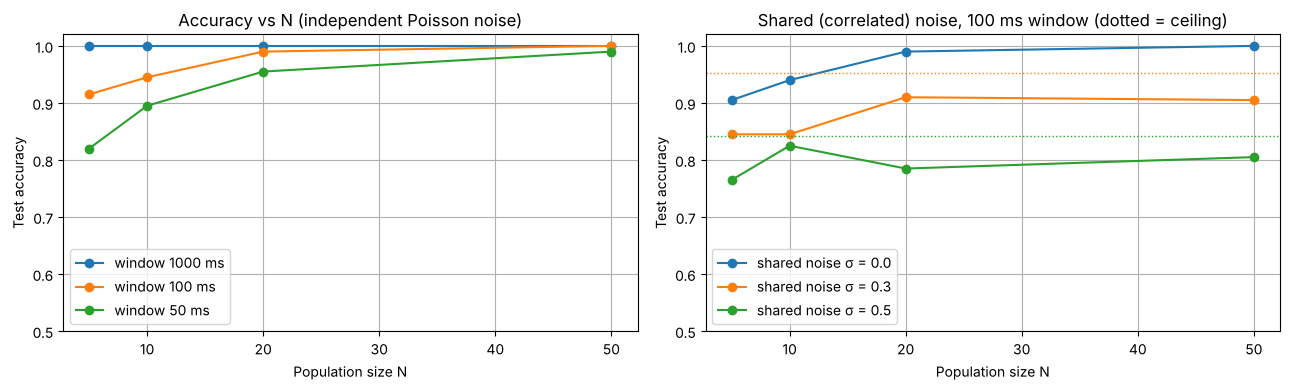

In [10]:
# TODO 5:

# Vary population size N: test N = 5, 10, 20, 50 and plot accuracy vs N.

# Add shared noise (correlation) and observe decoding accuracy drop.

def simulate_population_shared(stim, N=30, T=1.0, dt=0.001, shared_sd=0.0):
    t = np.arange(0, T, dt)
    rA = np.linspace(5, 25, N); rB = rA[::-1]
    base_r, other = (rA, rB) if stim == "A" else (rB, rA)
    c = shared_sd * np.random.randn()                       # one value shared by all neurons this trial
    rates = np.clip(base_r + c * (other - base_r), 0, None)
    spikes = np.array([poisson_spikes(r, t, dt) for r in rates])
    return spikes.sum(axis=1) / T

def decode_accuracy(N, T, shared_sd=0.0, n_trials=200):
    X, y = [], []
    for _ in range(n_trials):
        X.append(simulate_population_shared("A", N, T, shared_sd=shared_sd)); y.append(0)
        X.append(simulate_population_shared("B", N, T, shared_sd=shared_sd)); y.append(1)
    X, y = np.array(X), np.array(y)
    idx = np.random.permutation(len(y)); tr, te = idx[:len(y)//2], idx[len(y)//2:]
    w = X[tr][y[tr]==1].mean(0) - X[tr][y[tr]==0].mean(0)
    b = -0.5 * (X[tr][y[tr]==1].mean(0) + X[tr][y[tr]==0].mean(0)) @ w
    return ((X[te] @ w + b > 0).astype(int) == y[te]).mean()

np.random.seed(1)
Ns = [5, 10, 20, 50]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for Tw in [1.0, 0.1, 0.05]:
    accs = [decode_accuracy(N, Tw) for N in Ns]
    axes[0].plot(Ns, accs, 'o-', label=f"window {int(Tw*1000)} ms")
    print(f"independent noise, window {int(Tw*1000):>4} ms:", dict(zip(Ns, np.round(accs, 3))))
axes[0].set_xlabel("Population size N"); axes[0].set_ylabel("Test accuracy"); axes[0].set_ylim(0.5, 1.02)
axes[0].set_title("Accuracy vs N (independent Poisson noise)"); axes[0].legend(); axes[0].grid(True)

from math import erf, sqrt
for sd in [0.0, 0.3, 0.5]:
    accs = [decode_accuracy(N, 0.1, shared_sd=sd) for N in Ns]
    axes[1].plot(Ns, accs, 'o-', label=f"shared noise σ = {sd}")
    ceiling = 0.5 * (1 + erf(0.5 / (sd * sqrt(2)))) if sd > 0 else 1.0
    if sd > 0: axes[1].axhline(ceiling, ls=':', color=axes[1].lines[-1].get_color(), lw=1)
    print(f"shared σ={sd}, window 100 ms:", dict(zip(Ns, np.round(accs, 3))), f"| ceiling P(c<0.5) = {ceiling:.2f}")
axes[1].set_xlabel("Population size N"); axes[1].set_ylabel("Test accuracy"); axes[1].set_ylim(0.5, 1.02)
axes[1].set_title("Shared (correlated) noise, 100 ms window (dotted = ceiling)"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

#### Writing questions.

**1. Rate coding vs timing coding.** In rate coding the information is the number of spikes in a time window (e.g. stimulus intensity → firing rate, Part C), so the exact spike times do not matter and the code is robust but needs time to count spikes. In temporal coding the precise time of each spike (relative to an event or to other neurons) carries the information (Part D), which is fast and can carry more information per spike, but only if timing jitter is small: our detection rate collapsed once jitter exceeded the coincidence window.

**2. What refractory changes.** The refractory period removes spikes that would come too soon after the previous one. This caps the maximum firing rate at about 1/τ_ref, lowers the achieved rate for strong inputs (with 80 Hz input the rate fell as τ went 0 → 10 ms), and empties the short end of the ISI distribution (no ISIs below τ_ref). Spike trains become more regular than Poisson (CV < 1), and the rate–intensity curve saturates, so very strong stimuli can no longer be distinguished.

**3. How population size affects decoding.** With independent noise, larger populations average out Poisson variability, so accuracy rises with N. This matters most for short decoding windows: at 50 ms accuracy climbs from 0.82 with 5 neurons to 0.99 with 50 (100 ms: 0.92 → 1.0), while with 1 s windows even 5 neurons are perfect. Shared (correlated) noise that moves the whole population in the same direction as the signal cannot be averaged away. Accuracy then stops improving: about 0.85–0.91 for σ = 0.3 and 0.77–0.83 for σ = 0.5 at every N, just under the theoretical ceilings of 0.95 and 0.84 (the probability that the shared fluctuation does not flip the pattern). Correlations, not just neuron count, limit population codes.